# Creating an environment for AI training

As we presented in the first notebook, we must shape an environment for AI training, but before we can even do that, we must really think of how this will be used - the integration aspect.

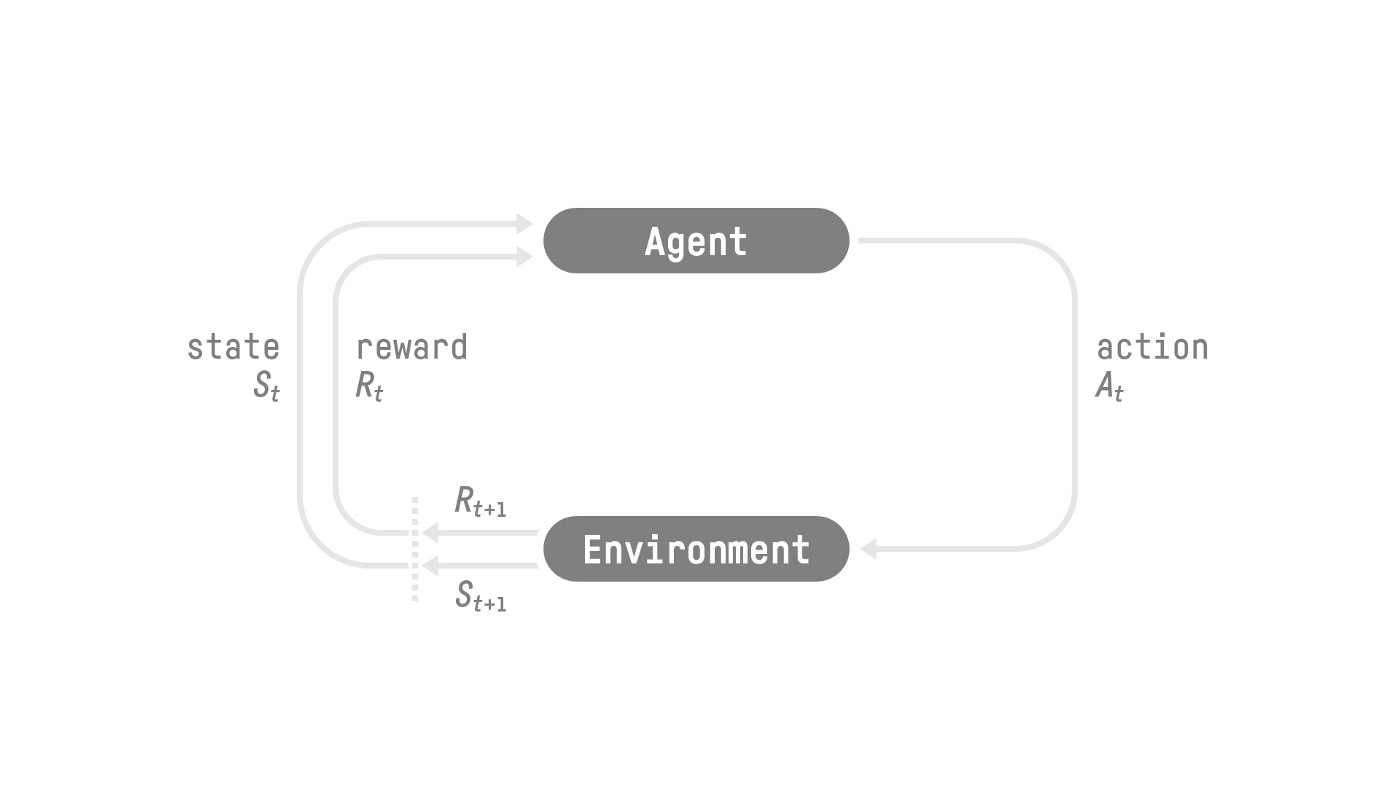

In [5]:
from IPython.display import Image
Image("https://huggingface.co/datasets/huggingface-deep-rl-course/course-images/resolve/main/en/unit1/RL_process.jpg", width=560)

This image represents the reinforcement learning loop.  
Imagine you were making a home video of your child playing a videogame for the first time.  

You framed the video well, so the child and controller were clearly in view and so was the game screen.  
If you were to watch the video frame by frame, you could navigate the same loop presented above, considering:
- `t` is the video frame you're looking at
- `Agent` is your child
- `Environment` is the game
- `action` is the combination of keys your child was pressing at frame `t`
- `state` is what's visible on the game screen at frame `t`
- `reward` is the game score change after applying the `action` to the `environment` at frame `t` and transitioning to `t+1`

Notice that the actions made in the environment at `t` influence state `t+1` and result in a reward.

Because we want to replicate this learning loop in code, we need to define the `environment` (game) to work frame by frame, accept `actions` from an `agent` which will modify the `state`, then give back a `reward` matching the updated state.

Applying the `action`, modifying the `state` and obtaining a reward is what is commonly referred to as a `step`.

The `horizon` represents the amount of time it takes to finish a level or the amount of time in which the `agent` can prove it is skilled, not just lucky.

Further reading I highly recommend: [The Reinforcement Learning Framework](https://huggingface.co/learn/deep-rl-course/unit1/rl-framework)

With the overall concept of an environment and its purpose clarified, we're ready to turn BeamNG.tech into a reinforcement learning environment. 

There are great videos on this topic: 
- [How to create a custom environment for Reinforcement Learning (6 minutes)](https://inv.nadeko.net/watch?&v=H2uUvhSKpWI);  
- [Custom Environments - Reinforcement Learning with Stable Baselines 3 (P.3)](https://inv.nadeko.net/watch?v=uKnjGn8fF70&listen=false)

The links are not directly youtube, they are for a youtube proxy service, but feel free to replace `inv.nadeko.net` with `youtube.com` and the URLs will then work directly on youtube.  
The first is an introduction to the subject while the second walks through the definition of an `Gymnasium` environment

Like stated in the first video, it doesn't take much research to notice the most commonly used library for defining environments to be integrated with reinforcement learning is [Gymnasium](https://pypi.org/project/gymnasium/) - a library which was started as `gym` by OpenAI.

So let's get started integrating BeamNG.tech with `Gymnasium`!

### Integrating BeamNG.tech with Gymnasium

#### Docs

We will need some documentation to start. We already have the building blocks needed to create this environment, we only need to understand where to place all the blocks.

1. [Gymnasium Environment Creation Guide](https://gymnasium.farama.org/tutorials/gymnasium_basics/environment_creation/)
2. [gymnasium-env-template](https://github.com/Farama-Foundation/gymnasium-env-template)
3. [gymnasium.Env](https://gymnasium.farama.org/api/env/)

I also found an interesting environment we could use as an example: [racecar_gym](https://github.com/axelbr/racecar_gym/)

#### Copying the reference environment

You will have to activate your python virtual environment, install the python package `copier` then run:

```bash
copier copy https://github.com/Farama-Foundation/gymnasium-env-template.git "src/env/gymnasium"
```

The command will ask for input, you can name the environment as you like, in this repo it is named `beamng_tech_env` and the license I chose is MIT.

#### Refactoring the example environment

This example environment is of the grid world game, a simple game where you navigate a grid to get to the exit.

We will have to remove the code that is there and replace it with our code.

In this example, the environment and the game are one and the same, but this isn't a condition, it was a design choice because the game is simple.

Let's see how our building blocks from before fit.  
Some of the building blocks were not explored fully before, now we have to become aware of all the details such as input ranges for controls, etc.

#### Defining Actions

##### Defining the action space

Spaces are explained very well in the Gymnasium documentation: [Spaces](https://gymnasium.farama.org/api/spaces/).

Gridworld already exemplifies the action space, as a discrete action space:

```python
        # We have 4 actions, corresponding to "right", "up", "left", "down", "right"
        self.action_space = spaces.Discrete(4)
```

And we can see an observation space, which is more complex:

```python
        # Observations are dictionaries with the agent's and the target's location.
        # Each location is encoded as an element of {0, ..., `size`}^2,
        # i.e. MultiDiscrete([size, size]).
        self.observation_space = spaces.Dict(
            {
                "agent": spaces.Box(0, size - 1, shape=(2,), dtype=int),
                "target": spaces.Box(0, size - 1, shape=(2,), dtype=int),
            }
        )
```

Our action space is not as simple as a single `spaces.Discrete` which takes unsigned integers, so we will have to use a `spaces.Dict` with nested `Box` or `Discrete` spaces, like in the `GridWorld` observation space.

These Box spaces are also commonly referred to as `continuous` spaces. When an action is continuous, it means that it can't be fully defined with a few finite values - like how the gearbox is defined - reverse, neutral, gear 1..N.

In our drifting example, the steering action is a perfect example of a continuous action, because you could turn the wheel 0.5 degrees to the left or  400 degrees to the right, really in any way that fits in the range of the steering wheel. It would also be possible to divide this continuous space in discrete ranges, such as -100,-80,-60..60,80,100 percent left to right, however it's likely a certain drift step would benefit more from exactly -73 percent - steering to the left 73% of the range. You could end up dividing the full range into too many steps for the discrete space to make sense, taking into consideration what they are designed to represent.

In the `GridWorld` example, we see that `spaces.Box` takes a shape argument, which we need to understand to see what fits in our case.

The `shape` argument takes a tuple and the numbers within define dimensions. 
In `GridWorld`, the shape of the environment (`observation_space`) is a set of two lists, both composed of two elements `shape=(2, )`, one for `agent` and one for `target`.

One list is a set of coordinates in the format [x, y] or [column, row]

If our observation space would have been a matrix, then we would need to just add a dimension in the shape tuple, which could have represented two coordinates for example: `shape(2, 2)`

If we have a black and white image as an observation, our shape becomes `shape(height, width)` so `shape(320,240)`, as an example for a b&w 320x240 image (our LiDAR BEV matches this shape).

For a color image, each pixel is made of three values (R G B), which means it has three values for every matrix position - its shape is `shape(height, width, channels)`, could be `shape(320,240, 3)` for a 320x240 color image.

##### Car controls
`beamngpy/src/beamngpy/vehicle/vehicle.py` defines the function `control` which has a docstring explaining the arguments and their ranges:

> `steering`: Rotation of the steering wheel, from `-1.0 to 1.0`.  
> `throttle`: Intensity of the throttle, from `0.0 to 1.0`.  
> `brake`: Intensity of the brake, from `0.0 to 1.0`.  
> `parkingbrake`: Intensity of the parkingbrake, from `0.0 to 1.0`.  
> `clutch`: Clutch level, from `0.0 to 1.0`.  
> `gear`: Gear to shift to, `-1 eq backwards, 0 eq neutral, 1 to X eq nth gear`  
> `is_adas`: Whether the input source is an ADAS system.

This same information is documented in [BeamNG.tech's documentation](https://documentation.beamng.com/api/beamngpy/master/beamngpy.html#beamngpy.Vehicle.control).

From these the actions we won't use the `clutch` (reserved for later maybe) and `is_adas` (because we're representing a driver).

We'll drop the `gear` requirement for now, just to start with something simple - I've experimented with random actions and it's very easy to kill the engine via random gear shifts. So even though we're not really happy with the arcade gearbox for drifting, it will have to do in the beginning, and we'll later improve our environment step by step.

Another interesting aspect is that we could combine throttle and brake into a single action, because both of them use half the range of a float (leaving the negative part of the range from -1.0 to 0.0 unused), with simple logic.

```python
combined = action['combined']
brake = 0.0
throttle = 0.0

if combined > 0.0:
    throttle = combined
else:
    brake = -combined
```

This also helps the AI because in the beginning when it's learning, it could easily shoot itself in the foot by controlling throttle and brake at the same time, so by actually combining the actions into one, we remove this footgun.  
With this, it still has two ways of braking (brake and parking brake) and just one for moving forward (acceleration), so it can still fail in this way, but this approach at least reduces some of that possibility.

To further reduce the possibility of driving with the parking brake on, we can define the full -1.0 to 1.0 range for the parking brake too, just dropping the control when it's under 0. This is not really needed, but logically it helps contrast the actions and it might speed up training.

```python
parkingbrake = action['parkingbrake']
if parkingbrake < 0.0
    parkingbrake = 0.0
```

With these details clarified, we can define the shape of our action space:

```python
self.action_space = spaces.Dict({
  # [steering, throttle/brake, parkingbrake]
  "controls": spaces.Box(
      #              s     t/b  p
      low=np.array([-1.0, -1.0, 0.0]),
      high=np.array([1.0,  1.0, 1.0]),
      dtype=np.float32,
  ),
  # gearbox automated via in-game mechanics
})
```

##### Defining the observation space

So now we know how to define `spaces`, but we need to take a step back and identify all of the elements of our observation space. In the previous chapter we listed what a driver normally observes when drifting:

>- RPM (I hear it and it's displayed in the dashboard)
>- Turbo pressure (there's usually a gauge)
>- The car's travel direction (not to be confused with its front direction)
>- IMU - rotation and G-forces (felt while driving)
>- Gear (I sometimes move my hand to the shifter, observing it)
>- Airspeed (I feel it, estimating via hearing and vision)
>- The environment (street) - implies vision for crash avoidance, so drifts can be linked further, to extend the reward.

Checking the `gear` is pointless if changing the gear is also an action, but it's important to know that when you request a gear shift in `Beam.NG.tech` it doesn't happen the exact next frame, which makes knowing whether the shift is complete or not important. Since we chose at first to avoid controlling gear shifts, it becomes more relevant especially now.

Some of the observations cannot be direct, at least not as we prepared this environment so far:
- `The environment (street)` maps to the BEV we have built previously, which encodes an elevation map of the street and distances to various surrounding high objects (even sidewalks).
- `The car's travel direction` is indirectly represented by the drift angle together with the airspeed
- We will drop the `Turbo pressure` observation because it's encoded into the `RPM` update rate as an effect

We'll also have to think of how to normalize all of the remaining environment observations into floats, in cases where they are not represented this way (such as RPM).  

[Normalization is strongly recommended](https://github.com/DLR-RM/stable-baselines3/blob/master/docs/guide/rl_tips.md#tips-and-tricks-when-creating-a-custom-environment) as without it [how the model learns can be affected](https://araffin.github.io/post/sac-massive-sim/), especially if you won't use just PPO as a training algorithm.

Let's set up an environment again to check these details.

In [1]:
from beamngpy import BeamNGpy, Scenario, Vehicle
from beamngpy.sensors import (
    Camera,
    AdvancedIMU,
    Damage,
    Electrics,
    Lidar,
    State,
    Timer,
    Ultrasonic,
    RoadsSensor,
)

beamng = BeamNGpy("localhost", 25252)
beamng.open()

scenario = Scenario("west_coast_usa", "beamngpy_feature_overview")
ego = Vehicle("ego", model="bx", part_config="pro_drift_M", color="Grey")
scenario.make(beamng)
beamng.scenario.load(scenario)

waypoints = scenario.find_waypoints()
waypoints = {w.name: w for w in waypoints}

# In this example we hardcode the waypoint
key = "Bridge15_C"
print(f"teleported to {key} out of {len(waypoints.keys())} locations")

scenario.add_vehicle(
    ego, pos=waypoints[key].pos, rot_quat=waypoints[key].rot
)

beamng.scenario.start()
print("Scenario is started")

teleported to Bridge15_C out of 838 locations
Scenario is started


In [2]:
# Disable driving assists
beamng.queue_lua_command('''
settings.setValue("steeringAutocenterEnabled", false)
settings.setValue("steeringSlowdownEnabled", false)
settings.setValue("steeringStabilizationEnabled", false)
settings.setValue("steeringUndersteerReductionEnabled", false)
settings.setValue("steeringLimitEnabled", false)
settings.setValue("autoClutch", true)
settings.setValue("autoThrottle", true)
settings.setValue("absBehavior", "off")
''')

# Fixed windowed resolution
beamng.settings.change("GraphicDisplayMode", "Windowed")
beamng.settings.change("GraphicDisplayResolutions", "640 480")
beamng.settings.apply_graphics()

# -- set deterministic
beamng.queue_lua_command('be:setPhysicsDeterministic(true)')

# -- set to a value that your PC can handle and also 20 / fpslimit * factor has to be an integer
fpsbase = 20
# -- maximum speed up factor
factor = 1
fpslimit = int(factor * fpsbase)
beamng.queue_lua_command(f"settings.setValue('fpsLimit', {fpslimit})")

beamng.queue_lua_command('settings.setValue("fpsLimitEnabled", true)')
iterations = 20 / fpslimit * factor
beamng.queue_lua_command(f'be:setPhysicsSpeedFactor({iterations})')

In [3]:
def setup_sensors(ego):
    # realistic manual gearbox dropped, arcade set
    ego.set_shift_mode("arcade")

    # Sensors
    electrics = Electrics()
    damage = Damage()
    timer = Timer()
    
    ego.sensors.attach("electrics", electrics)
    ego.sensors.attach("damage", damage)
    ego.sensors.attach("timer", timer)
    
imu = AdvancedIMU("imu", beamng, ego, gfx_update_time=0.01, is_send_immediately=True, is_dir_world_space=False, pos=(0, 0, 0.5))

setup_sensors(ego)
ego.sensors.poll()

We have a boolean that can tell us if the gearbox is shifting

In [4]:
print(ego.sensors['electrics']['is_shifting'])

False


In [5]:
print(ego.sensors['electrics'])

{'lowhighbeam_signal_L': 0.0, 'reverselight_filament': 0.0, 'gearModeIndex': 0.0, 'lowhighbeam_filament': 0.0, 'wheelspeed': 0.003406192386226977, 'horn': 0.0, 'airflowspeed': 0.051542996024564004, 'hoodCatchCoupler_attached': 1.0, 'door_L_coupler_notAttached': 0.0, 'oil': 0.0, 'running': True, 'lowhighBrake_filament': 0.7499030712883984, 'reverse_wigwag_L': 0.0, 'parking': 0.0, 'steering': 0.0, 'brakelight_signal_L': 1.0, 'brakelight_signal_R': 1.0, 'boostMax': 0.0, 'freezeState': False, 'gearboxMode': 'arcade', 'smoothShiftLogicAV': 0.06037368959152664, 'signal_L_filament': 0.0, 'accXSmooth': -0.01768256950947068, 'odometer': 0.023531978309583142, 'brake_input': 0.0, 'ignition': True, 'hasABS': 0.0, 'turnsignal': 0.0, 'trip': 0.023531978309583142, 'wheelThermals': {'RR': {'brakeSurfaceTemperature': 24.513482666015648, 'brakeCoreTemperature': 24.51362067158706, 'brakeThermalEfficiency': 0.9663154650820788}, 'RL': {'brakeSurfaceTemperature': 24.513482666015648, 'brakeCoreTemperature': 

And since we have the `maxrpm` in the car's electrics sensor, we can divide the current rpm to the max and get a percentage in float - normalizing the RPM value to something the AI can process.

In [6]:
print(min(1.0,ego.sensors['electrics']['rpm'] / ego.sensors["electrics"]["maxrpm"]))

0.11912108859447916


And let's look at the structure of the IMU data

In [7]:
data = imu.poll()
print(data)

{'dirZ': [-0.5307383455713205, 0.8474497690007249, 0.012070524463995022], 'mass': 1.5, 'accSmooth': [0.04823092880758688, -0.09828376601805944, -0.01400985395329404], 'dirX': [-0.8472934517255225, -0.5308733250787077, 0.016349904676374975], 'angAccel': [0.37850164191667823, -2.184613175994665, 1.3933027155065365], 'pos': [-148.2937108183142, 485.31586324892976, 75.13495416898135], 'angVelSmooth': [1.5089076148163381e-05, -0.00011710895120592383, 4.018938593185375e-05], 'time': 29.000001377426088, 'angVel': [0.00022427316526376406, 0.00028261856739884297, 0.0034656607752573654], 'dirY': [0.020263667910164696, -0.001549738994867797, 0.9997934697085566], 'accRaw': [-2.0736089668695405, 1.0994914118643941, -2.193592596345967]}


The values are explained in documentation: [beamngpy.sensors.AdvancedIMU.poll](https://documentation.beamng.com/api/beamngpy/master/beamngpy.html#beamngpy.sensors.AdvancedIMU.poll)

We can pass the `accRaw` and `angVel`, which are raw values representing acceleration in m/s^-2 and rotational velocity in rad/s respectively.  
We need to set some maximums in order to normalize these values between -1 and 1 floats

Raw values are probably better, since the values are tied to that frame `t`, instead of incorporating past values with a smoothing function.

The values are noisy when staying still, we could also force to 0 when airspeed < 1.

In [8]:
import numpy as np

IMU_ACC_MAX      = 20.0   # m/s^2  (~2 g per axis)   
IMU_ANGVEL_MAX   = 10.0   # rad/s

imu_data = imu.poll()
acc = np.clip(np.asarray(imu_data["accRaw"], np.float32) / IMU_ACC_MAX, -1.0, 1.0)
angvel = np.clip(np.asarray(imu_data["angVel"], np.float32) / IMU_ANGVEL_MAX, -1.0, 1.0)

print(acc, angvel)

[ 0.0949127  -0.06589102  0.09998702] [ 3.3138302e-05 -7.4468626e-05 -3.4642726e-04]


We still need to normalize the drift data.  
Let's check it again.

In [37]:
def read_drift(bng):
    """Drift telemetry as a dict. The lua side packs the fields into a
    pipe-delimited string (booleans as 1/0); we split and cast here, so no
    json round-trip is needed."""
    chunk = (
        "local s = gameplay_drift_scoring.getScore() "
        "local b2s = function(x) return x and 1 or 0 end "
        "return string.format('%s|%s|%s|%s|%s|%s', "
        "s.potentialScore, s.score, "
        "b2s(gameplay_drift_drift.getIsDrifting()), "
        "b2s(gameplay_drift_general.getFrozen()), "
        "gameplay_drift_drift.getCurrDegAngleSigned(), "
        "gameplay_drift_drift.getAirSpeed())"
    )
    raw = bng.queue_lua_command(chunk, response=True)
    try:
        p = str(raw).split("|")
        return {"potentialScore": float(p[0]), "score": float(p[1]),
                "isDrifting": p[2] == "1", "frozen": p[3] == "1",
                "angle": float(p[4]), "airSpeed": float(p[5])}
    except (TypeError, ValueError, IndexError):
        print("read_drift: unexpected lua response:", repr(raw))
        return {"potentialScore": 0.0, "score": 0.0, "isDrifting": False,
                "frozen": False, "angle": 0.0, "airSpeed": 0.0}

# quick probe: confirm the dict comes back with real numbers
print(read_drift(beamng))


{'potentialScore': 0.0, 'score': 0.0, 'isDrifting': False, 'frozen': False, 'angle': -94.017114618696, 'airSpeed': 0.00067128764389304}


The angle seems to need normalization, based on the `driftOptions` in the code: `lua/ge/extensions/gameplay/drift/drift.lua` seems to be between [-180, 180]:
```lua
-- ...
local driftOptions = {
  minAngle = 7,
  maxAngle = 165,
  allowDonut = false,
-- ...
```
Notice the `minAngle` and `maxAngle`, plus the returned value suggests that the range is `[-180, 180]`  
This means that we can divide by 180 to normalize to `[-1, 1]`.

In [13]:
print(read_drift(beamng)['angle']/180)

0.42556816087406113


The `airSpeed` in drift scoring is in kph (the airSpeed variable in `lua/ge/extensions/gameplay/drift/drift.lua` is named `kphAirSpeed`), which means we'll also have to normalize it. Let's check if it can be negative.  
I reversed the car and captured this reading, it seems to be always positive, which makes sense.

In [14]:
print(read_drift(beamng)['airSpeed'])

0.00088245390819408


We'll normalize by setting a max and dividing by the max. I'll choose 300 for the max - it should be near impossible to achieve, which means we won't affect the reading usually with this max.

In [16]:
print(min(300.0,read_drift(beamng)['airSpeed'])/300)

0.5384597728791334


I drove a bit to get the value above, which maps to 0.53 * 300 = 159 kph, which seems correct based on my gameplay  

At this point the only observation left is the BEV from the LiDAR, which is already normalized with the previous function, meaning we're ready to define the observation space!

In [38]:
import numpy as np
from gymnasium import spaces

# sensor value limits
IMU_ACC_MAX      = 20.0   # m/s^2  (~2 g per axis, covers hard drift loads)
IMU_ANGVEL_MAX   = 10.0   # rad/s
ANGLE_MAX        = 180.0  # drift angle, deg -> [-1, 1]
AIRSPEED_MAX_KPH = 300.0  # kph -> [0, 1]
BEV_N            = 64     # LiDAR BEV grid size from the previous chapter

# The full observation: one Dict space, one key per sensor channel.
# Every value is a float already normalized into a bounded range.
observation_space = spaces.Dict({
    "rpm":         spaces.Box(low=0.0,             high=1.0,            shape=(1,),           dtype=np.float32),
    "imu_acc":     spaces.Box(low=-1.0,            high=1.0,            shape=(3,),           dtype=np.float32),
    "imu_angvel":  spaces.Box(low=-1.0,            high=1.0,            shape=(3,),           dtype=np.float32),
    "drift_angle": spaces.Box(low=-1.0,            high=1.0,            shape=(1,),           dtype=np.float32),
    "airspeed":    spaces.Box(low=0.0,             high=1.0,            shape=(1,),           dtype=np.float32),
    "is_shifting": spaces.Box(low=0.0,             high=1.0,            shape=(1,),           dtype=np.float32),
    "bev":         spaces.Box(low=0.0,             high=1.0,            shape=(BEV_N, BEV_N), dtype=np.float32),
})

Now we could also test our observation space, before modifying the `GridWorld` example.
For this we'll write a function that gets one observation, which will be directly used in the Gymnasium environment

In [39]:
def get_observation():
    ego.sensors.poll()
    e = ego.sensors["electrics"]
    imu_data = imu.poll()
    drift = read_drift(beamng)

    # bulk mode returns a list of readings
    if isinstance(imu_data, list):        
        imu_data = imu_data[-1]

    acc    = np.clip(np.asarray(imu_data["accRaw"], np.float32) / IMU_ACC_MAX, -1.0, 1.0) if drift["airSpeed"] > 1.0 else np.zeros(3)
    angvel = np.clip(np.asarray(imu_data["angVel"], np.float32) / IMU_ANGVEL_MAX, -1.0, 1.0) if drift["airSpeed"] > 1.0 else np.zeros(3)

    # BEV from the LiDAR (built in the previous chapter)
    # we'll create mock data just for this one
    bev = np.full((BEV_N, BEV_N), 0.5, np.float32)
    if "lidar_bev" in globals() and "lidar" in globals():
        bev = np.nan_to_num(lidar_bev(lidar.poll()["pointCloud"], ego.state, drift, n=BEV_N), nan=0.5)

    return {
        "rpm":         np.clip(np.array([e["rpm"] / e["maxrpm"]], np.float32), 0.0, 1.0),
        "imu_acc":     acc,
        "imu_angvel":  angvel,
        "drift_angle": np.array([drift["angle"] / ANGLE_MAX], np.float32),
        "airspeed":    np.array([min(AIRSPEED_MAX_KPH, drift["airSpeed"]) / AIRSPEED_MAX_KPH], np.float32),
        "is_shifting": np.array([1.0 if e["is_shifting"] else 0.0], np.float32),
        "bev":         bev,
    }

obs = get_observation()
for k, v in obs.items():
    print(f"observation '{k}' value: \n{v}")

observation 'rpm' value: 
[0.12247406]
observation 'imu_acc' value: 
[0. 0. 0.]
observation 'imu_angvel' value: 
[0. 0. 0.]
observation 'drift_angle' value: 
[-0.4738264]
observation 'airspeed' value: 
[1.4320983e-06]
observation 'is_shifting' value: 
[0.]
observation 'bev' value: 
[[0.5 0.5 0.5 ... 0.5 0.5 0.5]
 [0.5 0.5 0.5 ... 0.5 0.5 0.5]
 [0.5 0.5 0.5 ... 0.5 0.5 0.5]
 ...
 [0.5 0.5 0.5 ... 0.5 0.5 0.5]
 [0.5 0.5 0.5 ... 0.5 0.5 0.5]
 [0.5 0.5 0.5 ... 0.5 0.5 0.5]]


Let's also check the [Timer](https://documentation.beamng.com/api/beamngpy/master/beamngpy.html#beamngpy.sensors.Timer), which will measure the progress towards the `horizon`, and how it can be reset, which we will do with our environment as it's part of the `Gymnasium` API.

Another option is the vehicle `.state["time"]` which needs more careful tracking but eliminates the need of a `Timer` sensor.

In [19]:
ego.sensors.poll()
print(ego.sensors['timer']['time'])

0.0


In [40]:
ego.sensors.poll()
print(ego.sensors['timer']['time'])
print(ego.state["time"])

185.70000276714563
186.50000885827467


There's `beamng.scenario.restart()` which restarts the scenario.  

In [42]:
DRIFT_CARS_6SPEED = [
    {"model": "bx", "part_config": "pro_drift_M"},
    {"model": "bastion", "part_config": "drift"},
    {"model": "etk800", "part_config": "858_drift_M"},
    {"model": "etkc", "part_config": "kc8_drift_M"},
    {"model": "etki", "part_config": "drift"},
    {"model": "fullsize", "part_config": "drift"},
    {"model": "sbr", "part_config": "drift"},
]

In [46]:
import random
import time

# before
ego.sensors.poll()
print(ego.sensors['timer']['time'])
print(ego.state["time"])

# vehicle switch
scenario.remove_vehicle(ego)
beamng.scenario.restart()
car = random.choice(DRIFT_CARS_6SPEED)
ego = Vehicle("ego", license="DRIFT", color="Red", **car)
scenario.add_vehicle(
    ego, pos=waypoints[key].pos, rot_quat=waypoints[key].rot
)
# pause physics / time
beamng.control.pause()

# after
setup_sensors(ego)
# advance exactly 1 second / 20 frames (blocks until done)
beamng.control.step(20)
ego.sensors.poll()
print(ego.sensors['timer']['time'])
print(ego.state["time"])
# advance exactly 1 frame (blocks until done)
beamng.control.step(1)
ego.sensors.poll()
print(ego.sensors['timer']['time'])
print(ego.state["time"])

125.25000186637044
356.8500169494655
1.4000000208616257
358.1500170112122
1.4500000216066837
358.20001701358706


You'll notice that `beamng.scenario.restart()` resets the `ego.sensors['timer']['time']` but doesn't change the `ego.state["time"]`. We still can use either one, but we'll need to save a reset timepoint to compare against when using the `ego.state["time"]` data. You could argue it makes sense for both datapoints, but I don't mind the horizon timespan being shortened by 1.45 seconds.

In [47]:
# unpause physics / time
beamng.control.resume()

And with this we have all the pieces necessary to build the `Gymnasium` environment, including some in the previous chapter.

We'll randomize the drift car on every reset, which will help the AI to learn techniques applicable to any car.

### Fitting all the blocks

We'll name our `Gymnasium` environment `BeamNGTechEnv`.  
What follows are the descriptions for the pieces of code we have so far and how they must fit into the environment definition. 

#### Game launch

This will be an internal function named `_first_time_setup` which
* starts the game
* loads a scenario
* spawns a car randomly
* sets game settings
* pauses physics

All of this setup is gated on a variable, checked to be `None` when attempting this setup and initialized during setup.

I placed it in the `reset` function of the Gymnasium environment, which is the first function to be called normally.

#### [Main API methods](https://gymnasium.farama.org/api/env/)

##### Reset

Besides the check for the `_first_time_setup` and `super().reset(seed=seed)` which seeds randomness, the reset:
* unpauses physics
* removes the vehicle spawned by `_first_time_setup`
* restarts the scenario which also resets scenario time
* adds a new vehicle and sets up sensors for it
* sleeps one second to settle the game and pauses the physics
* returns one observation and the info for it

##### Step

The step function steps the physics one frame while also applying an action, then calls modified versions of the `compute_reward` and `get_observation` functions, defined in the first chapter and in this chapter respectively.

##### Render

We don't need any logic to render, stepping includes rendering in our case.

##### Close

Simply calls `beamng.close()` if the `_first_time_setup` was ever completed.

The full environment code is available in `./src/env/gymnasium/beamng_tech_env/envs/beamng_tech.py`. Since it is likely changed in the current repository state, you may want to check the first commit of the `dev` branch, but the basics will likely hold true anyway.

##### Extras

From the `GridWorld` example we can just remove the extras in the `wrappers` folder, we won't use them.

#### Validating the environment

It's possible to validate the environment by using a function from `Gymnasium`: `check_env`.

```python
import numpy as np
import gymnasium as gym
from gymnasium.utils.env_checker import check_env

from beamng_tech_env.envs.beamng_tech import BeamNGTechEnv

env = gym.make("beamng_tech_env/BeamNGTech-v0.39", render_mode=render_mode)
check_env(env, skip_render_check=True)
env.close()
```

#### Next steps
Using inspiration from [multi_client.ipynb](./beamngpy/examples/multi_client.ipynb), we'll work on making our environment more efficient. It currently seems to work at about 4 FPS when stepping, so we need to think about ways to make training faster.